# TP2 — Machine Learning 2
## Modélisation de séries temporelles financières : ARIMA, résidus et volatilité GARCH

**Question centrale :** que peut-on réellement modéliser dans une série financière ?



---
# PARTIE 0 — Introduction financière

 **Concept**

Le TP1 posait une question de **direction** (hausse ou baisse demain ?). Le TP2 étudie deux objets différents :
- les **rendements** $r_t = \frac{P_t - P_{t-1}}{P_{t-1}}$ → direction et amplitude des variations ;
- la **volatilité** (l'écart-type des rendements) → le **risque**, c'est-à-dire l'intensité des variations, quel que soit leur sens.

Idée clé du TP : les rendements sont presque imprévisibles, mais **leur amplitude**, elle, a de la mémoire.

## 4.1 Questions préliminaires

 **Réponses**

**1. Pourquoi est-il difficile de prédire parfaitement le prix futur d'un actif financier ?**
Le prix intègre très vite toute l'information disponible (efficience des marchés) : ce qui le fait bouger demain, ce sont surtout des **nouvelles imprévisibles** (résultats d'entreprises, décisions des banques centrales, crises). Les relations statistiques changent dans le temps et le nombre d'acteurs et de facteurs est immense. Une partie du mouvement est donc **intrinsèquement aléatoire**.

**2. Pourquoi les rendements sont-ils souvent plus intéressants que les prix pour une analyse statistique ?**
Les prix ont une **tendance** et un **niveau qui change** (SPY ≈ 200 $ en 2015, ≈ 470 $ fin 2023) : leur moyenne et leur variance ne sont pas stables, ils sont **non stationnaires**. Les rendements, eux, fluctuent autour d'un niveau proche de 0 avec une échelle comparable dans le temps (une variation de 1 % a le même sens en 2015 et en 2023). Ils sont **proches de la stationnarité**, condition requise par la plupart des modèles statistiques (ARIMA, GARCH).

**3. Quelle est la différence entre prédire la direction du marché et modéliser le risque ?**
- **Direction** : on cherche le **signe** de $r_{t+1}$ (monte ou descend ?). C'est le problème du TP1, presque impossible au-delà du hasard.
- **Risque** : on cherche l'**amplitude probable** des variations, c'est-à-dire la variance $\text{Var}(r_{t+1})$, sans prétendre en connaître le sens. On peut savoir que « demain sera agité » sans savoir si ce sera à la hausse ou à la baisse.

**4. Pourquoi peut-on dire qu'une série financière mélange une partie structurée et une partie aléatoire ?**
On peut écrire $r_t = \underbrace{\mu_t}_{\text{prévisible}} + \underbrace{\varepsilon_t}_{\text{choc imprévisible}}$. La partie structurée comprend une faible tendance moyenne, une légère dépendance temporelle et surtout une **dynamique de la volatilité** (les périodes agitées durent). La partie aléatoire, ce sont les chocs d'information, qui dominent largement. Tout l'enjeu du TP est d'identifier ce qui est réellement exploitable.

### Installation et imports

Dans VS Code, utilise `%pip` (et non `!pip`) pour installer dans l'environnement du kernel, puis **redémarre le kernel** après la première installation.

In [1]:
# Installation des bibliothèques nécessaires (à exécuter une seule fois, puis redémarrer le kernel)
%pip install yfinance arch statsmodels -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Bibliothèques générales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Données financières
import yfinance as yf

# Séries temporelles
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.arima.model import ARIMA

# Modèle GARCH
from arch import arch_model

# Masquer les avertissements de statsmodels sur la fréquence de l'index (sans conséquence ici)
import warnings
warnings.filterwarnings("ignore")

# Affichage
plt.rcParams["figure.figsize"] = (12, 5)

---
# PARTIE 1 — Construction du dataset

 Comme au TP1, on travaille sur **SPY**, l'ETF qui réplique le S&P 500, cette fois de 2015 à fin 2023.

 **Correctif important** : `yf.download` renvoie des colonnes à deux niveaux (`Price` / `Ticker`, visible dans l'énoncé). Sans correction, `price = data["Close"]` est un **DataFrame** d'une colonne et non une **Série**. Ça a l'air de marcher, mais plusieurs TODO donnent alors des résultats faux sans message d'erreur : par exemple `len(returns[returns > 0])` compterait **toutes** les lignes (les négatives deviennent des `NaN` mais restent comptées), et `.autocorr()` n'existe pas pour un DataFrame. La ligne `droplevel` évite ce piège.

In [3]:
symbol = "SPY"

data = yf.download(
    symbol,
    start="2015-01-01",
    end="2024-01-01",
    auto_adjust=False
)

# Colonnes MultiIndex (Price, Ticker) -> colonnes simples
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.droplevel(1)

data = data[["Close", "Volume"]]
data = data.dropna()

data.head()

[*********************100%***********************]  1 of 1 completed


Price,Close,Volume
Date,,
2015-01-02,205.429993,121465900
2015-01-05,201.720001,169632600
2015-01-06,199.820007,209151400
2015-01-07,202.309998,125346700
2015-01-08,205.899994,147217800


## Question 1

 **Réponses**

**1. Que représente la colonne `Close` ?**
Le **prix de clôture** : le dernier prix auquel le SPY s'est échangé à la fin de chaque séance de bourse (16 h à New York). Avec `auto_adjust=False`, c'est le prix brut, non corrigé des dividendes.

**2. Que représente la colonne `Volume` ?**
Le **nombre de parts échangées** pendant la séance. C'est une mesure de l'**activité** et de la liquidité du marché : le volume explose généralement pendant les crises (beaucoup d'acteurs vendent ou se couvrent en même temps).

**3. Pourquoi travaille-t-on souvent avec les prix de clôture dans une première analyse ?**
- C'est **une valeur par jour**, à la même heure, donc des observations régulières et comparables d'un jour à l'autre.
- C'est le prix de référence du marché : il sert à valoriser les portefeuilles et à calculer les performances.
- C'est simple, disponible partout et suffisant pour calculer des rendements journaliers.

**4. Quelles limites cela peut-il avoir ?**
- On **perd l'information intrajournalière** : un jour peut chuter de 5 % puis remonter et clôturer à 0 % ; la clôture ne montre aucune agitation (les colonnes `High`/`Low` sont ignorées).
- On ignore les **sauts de nuit** entre la clôture et l'ouverture du lendemain.
- Le prix brut n'intègre **pas les dividendes** (le SPY en verse chaque trimestre) : les rendements sont légèrement sous-estimés et le prix baisse mécaniquement les jours de détachement. La colonne `Adj Close` corrige cela.
- Une seule observation par jour donne une estimation assez grossière de la volatilité.

---
# PARTIE 2 — Prix et rendements

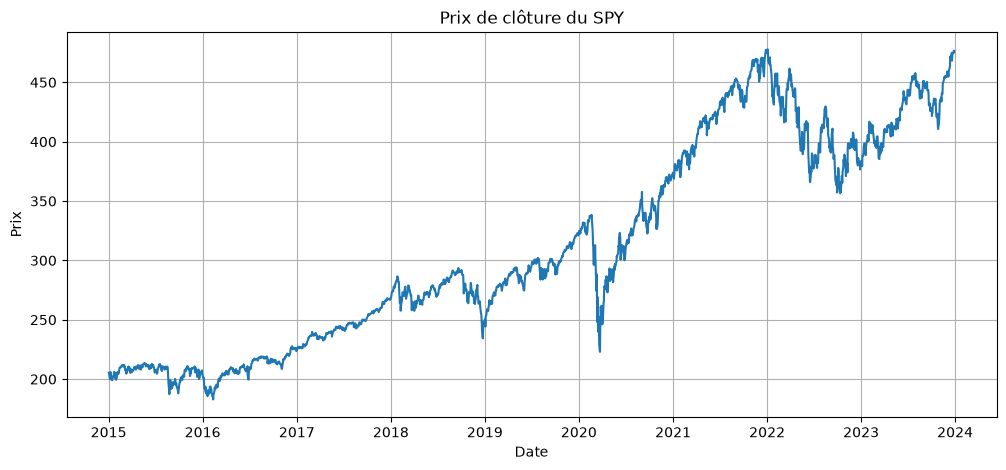

In [4]:
price = data["Close"]

plt.plot(price)
plt.title("Prix de clôture du SPY")
plt.xlabel("Date")
plt.ylabel("Prix")
plt.grid(True)
plt.show()

## Question 2

 **Réponses**

**1. La série des prix semble-t-elle fluctuer autour d'un niveau constant ?**
Non. Le prix passe d'environ 200 $ en 2015 à environ 470 $ fin 2023 : il n'y a aucun niveau autour duquel il oscille et vers lequel il revient.

**2. Observez-vous une tendance globale ?**
Oui, une **tendance haussière** de long terme, interrompue par des chutes marquées : fin 2018, le krach du Covid en **mars 2020** (≈ −34 % en un mois), et la baisse de **2022** (inflation et hausse des taux).

**3. Pourquoi cette série semble-t-elle difficile à considérer comme stationnaire ?**
Une série stationnaire a une moyenne et une variance stables dans le temps. Ici :
- la **moyenne** change (tendance) : la moyenne des prix sur 2015-2016 n'a rien à voir avec celle de 2021-2023 ;
- l'**amplitude des variations** en dollars augmente avec le niveau du prix (1 % de 450 $ fait plus que 1 % de 200 $) ;
- la série ne revient pas vers une valeur d'équilibre après un choc : les chocs sont **permanents** (comportement de marche aléatoire).

In [5]:
# Construction des rendements discrets
returns = price.pct_change()
returns = returns.dropna()

returns.head()

Date
2015-01-05   -0.018060
2015-01-06   -0.009419
2015-01-07    0.012461
2015-01-08    0.017745
2015-01-09   -0.008014
Name: Close, dtype: float64

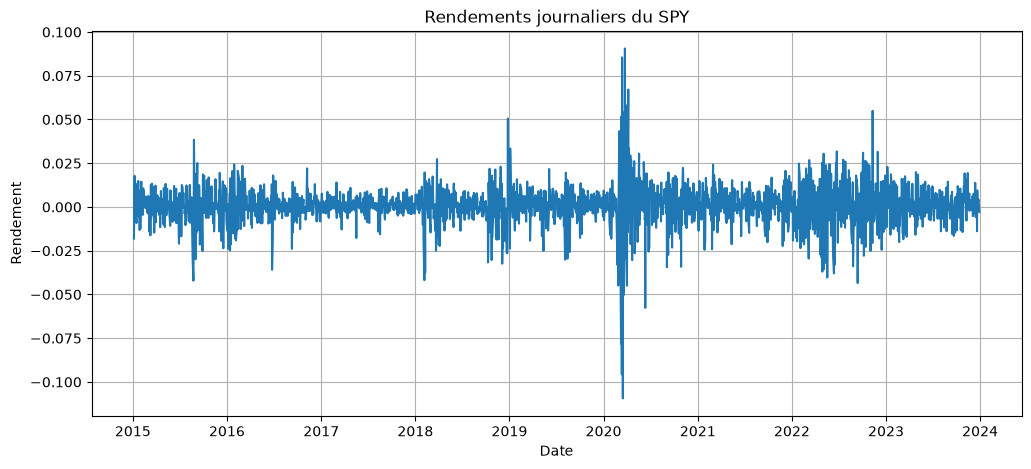

In [6]:
plt.plot(returns)
plt.title("Rendements journaliers du SPY")
plt.xlabel("Date")
plt.ylabel("Rendement")
plt.grid(True)
plt.show()

## Question 3

 **Réponses**

**1. Laquelle semble avoir une tendance plus marquée ?**
Les **prix**. Les rendements n'ont aucune tendance visible.

**2. Laquelle semble fluctuer davantage autour d'un niveau stable ?**
Les **rendements** : ils oscillent autour de **0** sur toute la période. On remarque cependant que l'**amplitude** des oscillations n'est pas constante (énorme en mars 2020, plus forte en 2022) : la moyenne est stable, mais la variance ne l'est pas tout à fait. C'est le point de départ de la partie 4.

**3. Pourquoi les rendements sont-ils souvent plus adaptés aux modèles statistiques temporels ?**
Passer des prix aux rendements revient à **différencier** la série (variation d'un jour à l'autre) : on supprime la tendance et la dépendance au niveau du prix. On obtient une série **proche de la stationnarité**, sans unité (en %), comparable dans le temps et entre actifs. Or ARIMA et GARCH supposent des propriétés statistiques stables pour que les paramètres estimés sur le passé restent valables dans le futur.

In [7]:
# TODO : calculer la moyenne et l'écart-type des rendements
mean_return = returns.mean()
std_return = returns.std()

print("Moyenne des rendements :", mean_return)
print("Écart-type des rendements :", std_return)

# Bonus : en version annualisée (≈ 252 jours de bourse par an)
print("Rendement moyen annualisé  : {:.1%}".format(mean_return * 252))
print("Volatilité annualisée      : {:.1%}".format(std_return * np.sqrt(252)))

Moyenne des rendements : 0.00043657647250376776
Écart-type des rendements : 0.011449255606619064
Rendement moyen annualisé  : 11.0%
Volatilité annualisée      : 18.2%


## Question 4

 Pour annualiser : la moyenne se multiplie par 252 (nombre de jours de bourse), l'écart-type par $\sqrt{252}$, car les variances de jours indépendants s'additionnent.

 **Réponses**

**1. La moyenne des rendements est-elle proche de zéro ?**
Oui : environ **0,05 % par jour**, très petit devant l'écart-type (environ 20 fois plus petit). Elle est pourtant positive et loin d'être négligeable à long terme : ≈ 12-13 % par an. C'est la **prime de risque** des actions, invisible au jour le jour mais réelle sur plusieurs années.

**2. Comment interpréter l'écart-type des rendements ?**
Environ **1,1-1,2 % par jour** : c'est l'amplitude typique d'une variation journalière. Un jour « normal », le SPY bouge d'environ ±1 %. Annualisé, cela donne ≈ 18 % de volatilité par an.

**3. Pourquoi l'écart-type est-il une première mesure simple de volatilité ?**
Il mesure la **dispersion** des rendements autour de leur moyenne, c'est-à-dire l'incertitude sur le résultat d'une journée, dans la même unité que les rendements. Il est simple à calculer et à interpréter. Sa limite : c'est **un seul nombre pour toute la période**, il suppose implicitement une volatilité constante, alors qu'elle varie fortement dans le temps (partie 4).

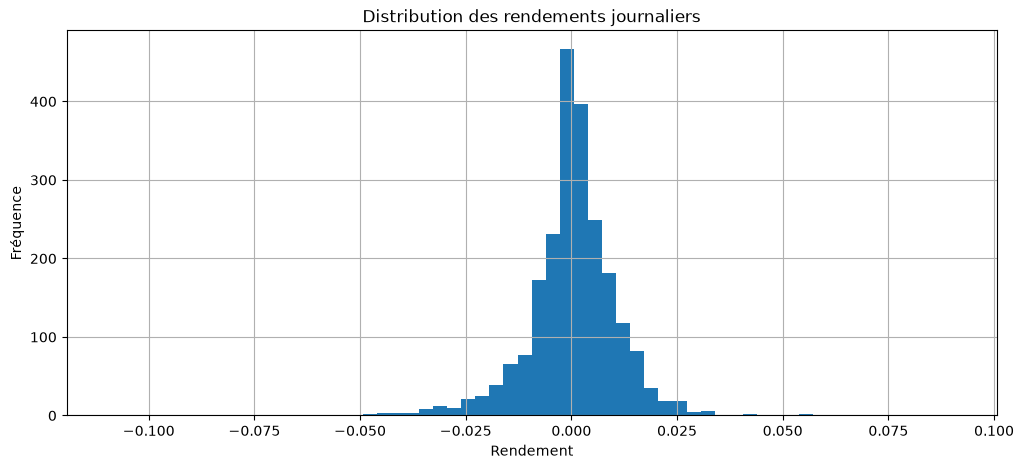

Asymétrie (skewness)        : -0.54   (0 pour une loi normale)
Kurtosis en excès           : 12.41   (0 pour une loi normale)
Pire jour  : 2020-03-16 -10.94%
Meilleur jour : 2020-03-24 9.06%


In [8]:
# Distribution des rendements
plt.hist(returns, bins=60)
plt.title("Distribution des rendements journaliers")
plt.xlabel("Rendement")
plt.ylabel("Fréquence")
plt.grid(True)
plt.show()

# Bonus : mesures de forme
print("Asymétrie (skewness)        :", round(returns.skew(), 2), "  (0 pour une loi normale)")
print("Kurtosis en excès           :", round(returns.kurt(), 2), "  (0 pour une loi normale)")
print("Pire jour  :", returns.idxmin().date(), f"{returns.min():.2%}")
print("Meilleur jour :", returns.idxmax().date(), f"{returns.max():.2%}")

## Question 5

 **Réponses**

**1. La distribution des rendements semble-t-elle parfaitement symétrique ?**
Non. Elle est centrée près de 0 et en forme de cloche, mais avec une **asymétrie négative** (skewness < 0, ≈ −0,85 dans le résumé ARIMA de l'énoncé) : la queue gauche est plus longue. Les fortes baisses sont plus violentes que les fortes hausses (« les marchés montent par l'escalier et descendent par l'ascenseur »).

**2. Observez-vous des rendements extrêmes ?**
Oui. Le pic central est plus pointu et les queues plus épaisses qu'une loi normale : c'est le phénomène de **queues épaisses** (*fat tails*), avec une kurtosis très élevée (≈ 17,6 dans l'énoncé, contre 3 pour une loi normale). On observe des journées autour de **−11 %** (16 mars 2020) et **+9 %** (24 mars 2020). Avec une loi normale de volatilité 1,2 %, une baisse de 11 % (≈ 9 écarts-types) n'arriverait pratiquement jamais.

**3. Pourquoi les événements extrêmes sont-ils importants en finance ?**
- Ce sont eux qui causent les **pertes les plus lourdes** : quelques jours de krach peuvent effacer des années de gains.
- Les modèles de risque fondés sur la loi normale **sous-estiment** leur fréquence, donc les pertes possibles (calcul de la VaR, des marges, des fonds propres des banques).
- Ils déclenchent des faillites, des ventes forcées et des effets de contagion entre marchés.

In [9]:
# TODO : calculer les rendements positifs et négatifs
positive_returns = returns[returns > 0]
negative_returns = returns[returns < 0]

print("Nombre de rendements positifs :", len(positive_returns))
print("Nombre de rendements négatifs :", len(negative_returns))
print("Proportion de jours haussiers : {:.1%}".format(len(positive_returns) / len(returns)))

# Bonus : amplitude moyenne des hausses et des baisses
print("Hausse moyenne : {:.2%} | Baisse moyenne : {:.2%}".format(positive_returns.mean(), negative_returns.mean()))

Nombre de rendements positifs : 1219
Nombre de rendements négatifs : 1038
Proportion de jours haussiers : 53.9%
Hausse moyenne : 0.74% | Baisse moyenne : -0.77%


## Question 6

 **Réponses**

**1. Les rendements positifs et négatifs sont-ils équilibrés ?**
Presque : environ **54-55 % de jours haussiers** contre 45-46 % de jours baissiers. Il y a un léger déséquilibre en faveur de la hausse, cohérent avec la moyenne légèrement positive. On remarque aussi que les baisses sont en moyenne un peu plus fortes que les hausses (asymétrie de la question 5).

**2. Que cela suggère-t-il sur la difficulté de prédire la direction du marché ?**
Que c'est **très difficile** : une stratégie naïve « toujours prédire hausse » a déjà ≈ 54-55 % de réussite. Un modèle doit faire mieux que cette référence, alors que le signe d'un rendement est presque aussi incertain qu'un pile ou face légèrement biaisé.

**3. Quel lien peut-on faire avec le TP1 ?**
C'est exactement la **baseline** du TP1 : la régression logistique, le Random Forest et le réseau de neurones obtenaient tous une accuracy proche de cette proportion de jours haussiers, sans la battre clairement. Ce comptage explique pourquoi : la classe majoritaire donne déjà ≈ 54 %, et il y a très peu de signal à ajouter par-dessus.

---
# PARTIE 3 — Stationnarité

 **Concept : le test ADF (Augmented Dickey-Fuller)**

On modélise $\Delta X_t = \alpha + \gamma X_{t-1} + \sum_i \delta_i \Delta X_{t-i} + \varepsilon_t$ et on teste :
- $H_0$ : $\gamma = 0$ → la série possède une **racine unitaire** → **non stationnaire** (marche aléatoire : un choc a un effet permanent) ;
- $H_1$ : $\gamma < 0$ → la série **revient vers sa moyenne** → stationnaire.

**Règle de décision** : si la p-value < 0,05, on **rejette $H_0$** → la série est considérée comme stationnaire. Si la p-value est grande, on ne peut pas rejeter la non-stationnarité.

In [10]:
# Test ADF sur la série des prix
adf_price = adfuller(price.dropna())

print("Test ADF sur les prix")
print("Statistique ADF :", adf_price[0])
print("p-value :", adf_price[1])

Test ADF sur les prix
Statistique ADF : -0.43968699175985987
p-value : 0.9032586255897933


In [11]:
# Test ADF sur la série des rendements
adf_returns = adfuller(returns.dropna())

print("Test ADF sur les rendements")
print("Statistique ADF :", adf_returns[0])
print("p-value :", adf_returns[1])

Test ADF sur les rendements
Statistique ADF : -14.88693065735069
p-value : 1.5783669081177703e-27


## Question 7

 **Réponses**

**1. Quelle est l'hypothèse nulle du test ADF ?**
$H_0$ : la série possède une **racine unitaire**, c'est-à-dire qu'elle est **non stationnaire**. L'hypothèse alternative est que la série est stationnaire.

**2. Comparez la p-value obtenue pour les prix et pour les rendements.**
- Prix : statistique ≈ −0,44, **p-value ≈ 0,90** → très élevée, on **ne rejette pas** $H_0$.
- Rendements : statistique ≈ −14,9, **p-value ≈ 1,6 × 10⁻²⁷** → quasiment nulle, on **rejette** $H_0$ très largement.

**3. Quelle série semble la plus proche d'une dynamique stationnaire ?**
Les **rendements**. Les prix se comportent comme une marche aléatoire (non stationnaire).

**4. Pourquoi ce résultat est-il cohérent avec les graphiques précédents ?**
Le graphique des prix montre une tendance et aucun niveau de retour, ce qui est la définition visuelle d'une racine unitaire. Le graphique des rendements montre des oscillations autour de 0 avec retour permanent vers ce niveau. Le test confirme formellement ce que l'œil voyait. Cela justifie aussi le choix de **d = 0** dans l'ARIMA sur les rendements (partie 6) : la série est déjà stationnaire, pas besoin de la différencier. Un ARIMA(p, **1**, q) sur les prix serait à peu près équivalent.

*Nuance :* l'ADF teste la stationnarité de la **moyenne** ; il ne détecte pas que la **variance** des rendements change dans le temps (partie 4).

In [12]:
# TODO : fonction qui applique le test ADF et affiche uniquement la p-value
def print_adf_pvalue(series, name):
    p_value = adfuller(series.dropna())[1]
    print("p-value ADF pour", name, ":", p_value)

print_adf_pvalue(price, "les prix")
print_adf_pvalue(returns, "les rendements")

p-value ADF pour les prix : 0.9032586255897933
p-value ADF pour les rendements : 1.5783669081177703e-27


---
# PARTIE 4 — Volatilité et risque

 **Concept** : $|r_t|$ (valeur absolue) mesure l'**amplitude** du mouvement du jour, sans son signe. C'est une approximation bruitée de la volatilité de ce jour. La **volatilité glissante** sur 20 jours (≈ un mois de bourse) lisse ce bruit.

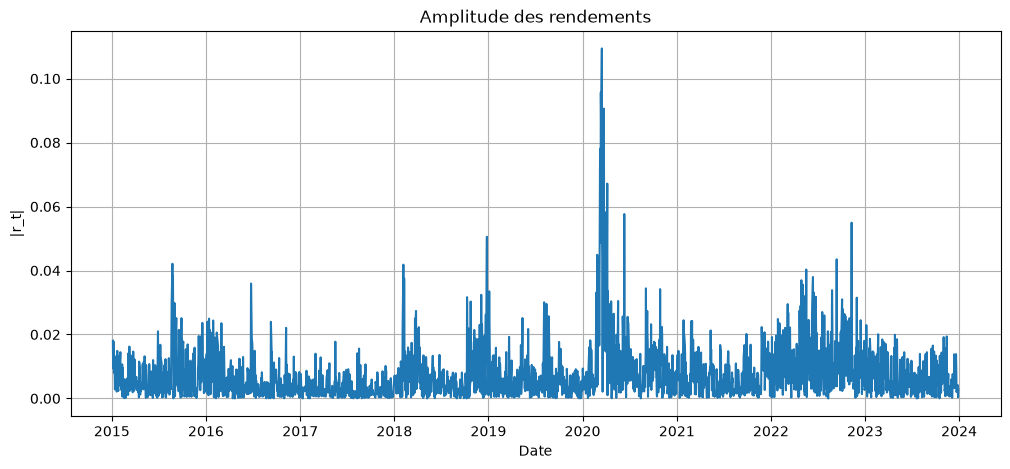

In [13]:
# Valeur absolue des rendements
abs_returns = np.abs(returns)

plt.plot(abs_returns)
plt.title("Amplitude des rendements")
plt.xlabel("Date")
plt.ylabel("|r_t|")
plt.grid(True)
plt.show()

## Question 8

 **Réponses**

**1. Les fluctuations semblent-elles réparties uniformément dans le temps ?**
Non. On voit de longues périodes calmes (2017, 2019, 2021) où $|r_t|$ reste presque toujours sous 1 %, et des périodes très agitées (début 2018, fin 2018, **mars-avril 2020**, 2022).

**2. Observez-vous des périodes où les variations restent durablement élevées ?**
Oui : les grands mouvements arrivent **en grappes**. En mars 2020, les variations de 4 à 10 % se succèdent pendant plusieurs semaines ; en 2022, l'agitation dure presque toute l'année. Un jour très agité est généralement suivi d'autres jours agités : c'est le **clustering de volatilité** (*volatility clustering*).

**3. Pourquoi peut-on dire que le risque semble évoluer par régimes ?**
Parce que la série alterne entre des **états persistants** : un régime « calme » à faible volatilité qui dure des mois, et un régime « crise » à forte volatilité qui dure des semaines ou des mois. On ne saute pas au hasard d'un jour calme à un jour agité : le niveau de risque d'aujourd'hui renseigne sur celui de demain.

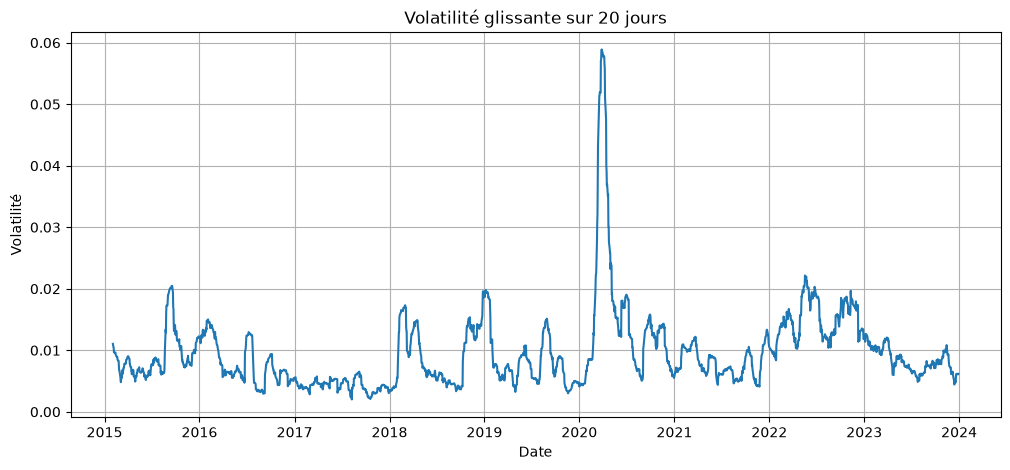

In [14]:
# Volatilité glissante
rolling_volatility = returns.rolling(window=20).std()

plt.plot(rolling_volatility)
plt.title("Volatilité glissante sur 20 jours")
plt.xlabel("Date")
plt.ylabel("Volatilité")
plt.grid(True)
plt.show()

## Question 9

 **Réponses**

**1. La volatilité semble-t-elle constante dans le temps ?**
Non. Elle varie d'environ **0,3-0,5 % par jour** dans les périodes calmes (2017) à plus de **5 % par jour** en mars 2020, soit un rapport de plus de 10.

**2. Que représentent les pics de volatilité ?**
Des **périodes de stress** sur les marchés, où l'incertitude explose : février 2018 (krach du « Volmageddon »), décembre 2018 (craintes sur les taux de la Fed et la guerre commerciale), **mars 2020 (Covid)**, 2022 (inflation, hausse rapide des taux, guerre en Ukraine).

**3. Pourquoi la volatilité est-elle une information importante en finance ?**
- Elle mesure le **risque** et sert à calculer les pertes potentielles (Value at Risk).
- Elle détermine le **prix des options** (une option vaut plus quand la volatilité est forte).
- Elle sert à **dimensionner les positions** (réduire son exposition quand la volatilité monte), à fixer les marges et les exigences de fonds propres des banques.

**4. Pourquoi un investisseur s'intéresse-t-il autant au risque qu'au rendement ?**
Parce que deux placements au même rendement moyen ne se valent pas : celui qui oscille fortement peut imposer une perte de 30 % au moment où l'investisseur doit vendre. Les investisseurs sont **averses au risque** : ils raisonnent en **rendement ajusté du risque** (ratio de Sharpe = rendement / volatilité). Et contrairement au rendement, le risque est **en partie prévisible**, donc on peut le gérer activement.

In [15]:
# TODO : date correspondant à la volatilité maximale
max_vol_date = rolling_volatility.idxmax()
max_vol_value = rolling_volatility.max()

print("Date de volatilité maximale :", max_vol_date)
print("Valeur maximale :", max_vol_value)

Date de volatilité maximale : 2020-03-27 00:00:00
Valeur maximale : 0.05890093517156176


## Question 10

 **Réponses**

**1. À quelle période correspond le pic de volatilité ?**
À **mars 2020** (le maximum de la volatilité sur 20 jours tombe autour de la fin mars - début avril 2020, quand la fenêtre contient toute la phase de krach). La volatilité journalière atteint alors environ 5-6 %, soit près de 90 % en annualisé.

**2. Quel événement économique ou financier pourrait expliquer ce comportement ?**
La **pandémie de Covid-19** : confinements en Europe et aux États-Unis, arrêt brutal de l'économie mondiale, effondrement du prix du pétrole, ventes paniques. Le S&P 500 a perdu environ un tiers de sa valeur en un mois, avec plusieurs journées à ±9 % et des déclenchements de coupe-circuits (suspension des cotations). L'intervention massive de la Fed et des gouvernements a ensuite provoqué des rebonds tout aussi violents.

**3. Pourquoi les crises financières provoquent-elles souvent une explosion de volatilité ?**
- **Incertitude extrême** : personne ne sait évaluer l'impact de l'événement, chaque nouvelle provoque une réévaluation brutale.
- **Ventes forcées** : appels de marge, fonds qui doivent réduire leur exposition, stratégies de gestion du risque qui vendent mécaniquement quand la volatilité monte, ce qui fait encore baisser les prix.
- **Liquidité en baisse** : moins d'acheteurs, donc chaque ordre fait davantage bouger le prix.
- **Effets de panique et de contagion**, puis rebonds brutaux quand les autorités interviennent.

---
# PARTIE 5 — Autocorrélation et mémoire temporelle

 **Concept**

L'**autocorrélation au retard $k$** est la corrélation entre la série et sa version décalée de $k$ jours : $\rho(k) = \text{Corr}(r_t, r_{t-k})$.
- $\rho(1)$ proche de 1 : un jour de hausse est presque toujours suivi d'une hausse.
- $\rho(1)$ proche de 0 : aujourd'hui ne dit rien de demain.

Le graphique **ACF** affiche $\rho(k)$ pour $k = 1 \dots 30$. La **zone bleue** est l'intervalle de confiance à 95 % sous l'hypothèse d'absence d'autocorrélation (≈ $\pm 1{,}96/\sqrt{n}$ ≈ ±0,04 ici) : un bâton qui en sort est statistiquement significatif. Le bâton au retard 0 vaut toujours 1 (une série est parfaitement corrélée avec elle-même), on l'ignore.

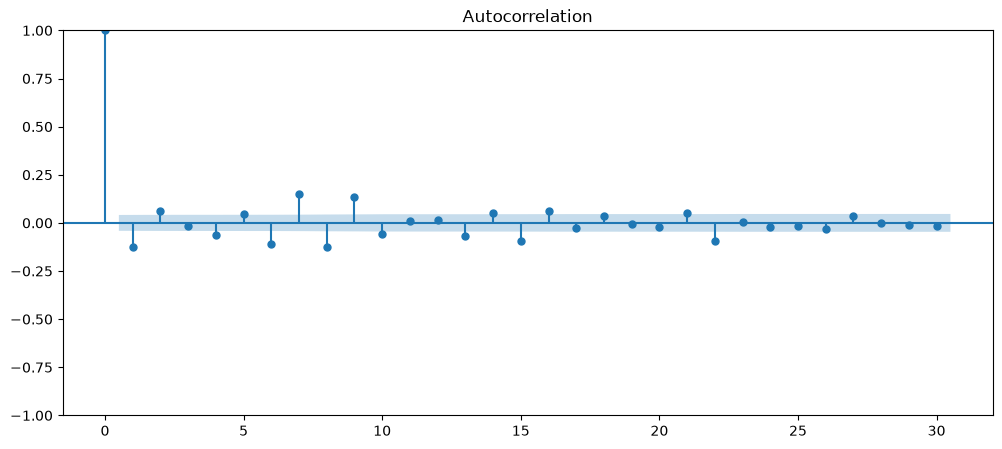

In [16]:
# Fonction d'autocorrélation des rendements
plot_acf(returns, lags=30)
plt.show()

## Question 11

 **Réponses**

**1. Les rendements présentent-ils une forte autocorrélation ?**
Non. Toutes les autocorrélations sont **très faibles** (en valeur absolue, de l'ordre de 0,1 au maximum, la plupart dans la zone bleue).

**2. Les premières autocorrélations semblent-elles proches de zéro ?**
Oui, globalement. Quelques retards (souvent 1 et 2) sortent légèrement de la zone bleue avec une valeur **négative**. C'est un faible effet de **retour à la moyenne** à court terme, largement dû aux périodes de crise où les fortes baisses sont suivies de forts rebonds (mars 2020). Mais l'effet est minuscule.

**3. Que peut-on conclure sur la prédiction linéaire des rendements ?**
Les rendements passés n'expliquent qu'une **part infime** des rendements futurs : avec $\rho(1) \approx -0{,}1$, un modèle linéaire explique au mieux $\rho^2 \approx 1\,\%$ de la variance. La prédiction linéaire des rendements est donc **presque inutile en pratique**, et l'avantage disparaîtrait avec les coûts de transaction.

**4. Pourquoi ce résultat est-il cohérent avec l'idée d'un marché relativement efficace ?**
Si les rendements étaient fortement autocorrélés (par exemple « une hausse est suivie d'une hausse »), les investisseurs achèteraient après chaque hausse, ce qui ferait monter le prix **dès aujourd'hui** et ferait disparaître la prévisibilité de demain. Dans un marché efficace, l'information passée est déjà intégrée dans le prix : les rendements doivent être **proches d'un bruit non prévisible**, ce que montre l'ACF.

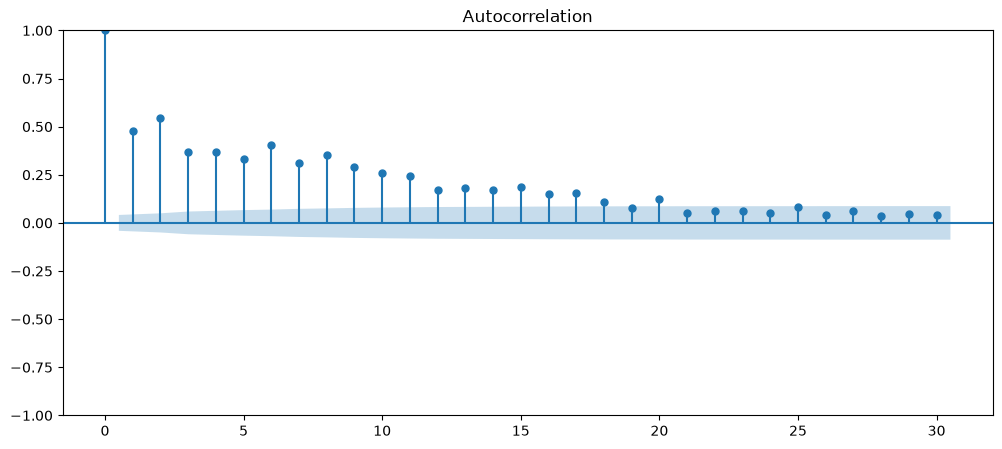

In [17]:
# Fonction d'autocorrélation des rendements au carré
plot_acf(returns**2, lags=30)
plt.show()

## Question 12

 **Réponses**

**1. Quelle série semble posséder davantage de mémoire temporelle ?**
Les **rendements au carré**, très clairement. Presque tous les bâtons sont positifs et sortent de la zone bleue, et ils **décroissent lentement** sur 30 jours : la dépendance dure plusieurs semaines.

**2. Pourquoi les rendements au carré sont-ils liés à la volatilité ?**
Comme la moyenne des rendements est proche de 0, $\text{Var}(r_t) = E[r_t^2] - E[r_t]^2 \approx E[r_t^2]$. Le carré $r_t^2$ est donc une **mesure ponctuelle (bruitée) de la variance** du jour : il est grand quand le marché bouge beaucoup, quel que soit le sens. Élever au carré **supprime le signe** (la direction, imprévisible) et garde l'**amplitude** (le risque).

**3. Quel lien peut-on faire avec le phénomène de volatility clustering vu dans le CM2 ?**
C'est sa **preuve statistique**. Une autocorrélation positive de $r_t^2$ signifie : un grand mouvement aujourd'hui (dans n'importe quel sens) rend probable un grand mouvement demain, et un jour calme est suivi de jours calmes. C'est exactement le clustering observé à la question 8.

**Conclusion clé du TP** : les rendements sont **non corrélés** (direction imprévisible) mais **pas indépendants** (leur amplitude a de la mémoire). Le risque est donc en partie prévisible, alors que la direction ne l'est presque pas. C'est ce qui motive GARCH.

In [18]:
# TODO : autocorrélation empirique au retard 1
acf_lag1 = returns.autocorr(lag=1)

print("Autocorrélation empirique au retard 1 :", acf_lag1)

# Bonus : comparaison avec les rendements au carré
print("Autocorrélation au retard 1 des rendements au carré :", (returns**2).autocorr(lag=1))

Autocorrélation empirique au retard 1 : -0.12462917296150142
Autocorrélation au retard 1 des rendements au carré : 0.4770353409558565


## Question 13

 **Réponses**

**1. L'autocorrélation empirique obtenue est-elle forte ?**
Non. Elle est faible et légèrement **négative** (de l'ordre de −0,1 à −0,2 sur 2015-2023, l'effet étant tiré par les rebonds de mars 2020). À comparer avec celle des rendements au carré, nettement positive et plus élevée.

**2. Que signifierait une autocorrélation très positive ?**
Un phénomène de **momentum (tendance)** : une hausse aujourd'hui serait très probablement suivie d'une hausse demain, une baisse d'une baisse. Il suffirait de « suivre la tendance » pour gagner, ce qui serait vite exploité et disparaîtrait.

**3. Que signifierait une autocorrélation très négative ?**
Un **retour à la moyenne** (mean reversion) : une hausse serait suivie d'une baisse et inversement, la série zigzaguerait. Il suffirait de jouer contre le mouvement du jour.

**4. Pourquoi une autocorrélation proche de zéro complique-t-elle la prédiction ?**
Parce que le passé ne contient alors **presque aucune information linéaire** sur le futur. La meilleure prévision linéaire de $r_{t+1}$ devient simplement la **moyenne** des rendements (≈ 0) : tout modèle de type AR ou ARMA produit des prévisions plates et ne fait pas mieux que « prédire 0 ».

---
# PARTIE 6 — Modélisation ARIMA

 **Concept : ARIMA(p, d, q)**
- **AR(p)** — autorégressif : la valeur dépend de ses $p$ valeurs passées : $X_t = c + \varphi_1 X_{t-1} + \dots + \varphi_p X_{t-p} + \varepsilon_t$.
- **I(d)** — intégré : on différencie la série $d$ fois pour la rendre stationnaire ($d=1$ : on modélise $X_t - X_{t-1}$).
- **MA(q)** — moyenne mobile : la valeur dépend des $q$ **chocs** passés (erreurs de prévision) : $X_t = c + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \dots$

Ici **ARIMA(1, 0, 1)** sur les rendements :
$$r_t = c + \varphi_1 r_{t-1} + \varepsilon_t + \theta_1 \varepsilon_{t-1}$$
avec $d = 0$ car les rendements sont déjà stationnaires (test ADF).

In [19]:
# Séparation train / test
split_index = int(len(returns) * 0.8)

train_returns = returns.iloc[:split_index]
test_returns = returns.iloc[split_index:]

print("Nombre d'observations train :", len(train_returns))
print("Nombre d'observations test :", len(test_returns))
print("Train :", train_returns.index.min().date(), "->", train_returns.index.max().date())
print("Test  :", test_returns.index.min().date(), "->", test_returns.index.max().date())

Nombre d'observations train : 1810
Nombre d'observations test : 453
Train : 2015-01-05 -> 2022-03-11
Test  : 2022-03-14 -> 2023-12-29


## Question 14

 **Réponses**

**1. Pourquoi doit-on respecter l'ordre chronologique des données ?**
Parce qu'en conditions réelles on prédit **toujours le futur à partir du passé**. Le jeu de test doit être **postérieur** au jeu d'entraînement pour simuler cette situation. De plus, un modèle ARIMA est par nature une relation entre $X_t$ et ses valeurs **précédentes** : l'ordre des observations fait partie des données.

**2. Pourquoi un mélange aléatoire serait-il problématique ici ?**
- Il **détruirait la structure temporelle** que l'on cherche à modéliser : $r_{t-1}$ ne serait plus la valeur de la veille.
- Le train contiendrait des jours de 2023 et le test des jours de 2016 : on évaluerait le modèle sur sa capacité à « boucher les trous » au milieu de périodes déjà vues, pas à prévoir.
- Avec le clustering de volatilité, un jour de test serait entouré de jours d'entraînement de la même période (même régime) : performances trop optimistes.

**3. Quel type de fuite d'information pourrait apparaître ?**
Une **fuite temporelle** (*look-ahead bias*) : le modèle utiliserait des informations du **futur** pour prédire le passé (par exemple, apprendre le niveau de volatilité de 2022 en prédisant un jour de 2022). Les scores obtenus seraient artificiellement bons et s'effondreraient en production.

In [23]:
# Estimation d'un modèle ARIMA(1,0,1)
arima_model = ARIMA(train_returns.reset_index(drop=True), order=(1, 0, 1))
arima_result = arima_model.fit()
print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 1810
Model:                 ARIMA(1, 0, 1)   Log Likelihood                5578.165
Date:                Wed, 07 Oct 2026   AIC                         -11148.330
Time:                        21:52:23   BIC                         -11126.326
Sample:                             0   HQIC                        -11140.209
                               - 1810                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0005      0.000      1.826      0.068   -3.34e-05       0.001
ar.L1         -0.4905      0.040    -12.395      0.000      -0.568      -0.413
ma.L1          0.3387      0.043      7.827      0.0

## Question 15

 **Comment lire le résumé**
- `coef` : valeur estimée ; `std err` : incertitude ; `z` = coef / std err ; `P>|z|` : p-value du test « le coefficient vaut 0 ». Si p < 0,05, le coefficient est **significatif**.
- En bas : **Ljung-Box** (autocorrélation restante des résidus), **Jarque-Bera** (normalité des résidus), **Heteroskedasticity** (variance constante ?), **Skew** et **Kurtosis** (forme de la distribution).

 **Réponses**

**1. Quel paramètre correspond à la composante autorégressive ?**
`ar.L1` = $\varphi_1$ ≈ **−0,49** : le coefficient sur le rendement de la veille $r_{t-1}$.

**2. Quel paramètre correspond à la composante moyenne mobile ?**
`ma.L1` = $\theta_1$ ≈ **+0,34** : le coefficient sur le choc de la veille $\varepsilon_{t-1}$.

(Les autres : `const` ≈ 0,0005, le rendement moyen journalier ≈ 0,05 % ; `sigma2` ≈ 0,0001, la variance des chocs, soit un écart-type ≈ 1,1 %.)

**3. Certains paramètres semblent-ils statistiquement significatifs ?**
Oui : `ar.L1` (p ≈ 0,000) et `ma.L1` (p ≈ 0,000) sont très significatifs. La constante ne l'est pas tout à fait au seuil de 5 % (p ≈ 0,068).

**4. Pourquoi faut-il rester prudent dans l'interprétation financière ?**
- **Les deux coefficients se compensent** : AR = −0,49 et MA = +0,34 sont de signes opposés et de tailles proches. L'effet net sur la prévision est faible : l'autocorrélation implicite au retard 1 ne vaut que ≈ −0,16, et elle décroît très vite. Des coefficients « significatifs » ne veulent pas dire un **effet économiquement important**.
- Les tests supposent des résidus normaux et de variance constante. Or le bas du résumé montre l'inverse : **Jarque-Bera ≈ 16 000 (p = 0)** → résidus non normaux ; **kurtosis ≈ 17,6** → queues très épaisses ; **H ≈ 2,9 (p = 0)** → variance non constante. Les p-values sont donc à prendre avec précaution.
- L'effet est probablement **tiré par quelques jours extrêmes** (mars 2020) et peut ne pas se reproduire hors de l'échantillon.
- Une relation statistique sur le passé n'implique pas une **stratégie rentable** : coûts de transaction, instabilité des paramètres dans le temps.

In [24]:
# Prévision sur la période de test
forecast = arima_result.forecast(steps=len(test_returns))
forecast.index = test_returns.index
forecast.head()

Date
2022-03-14    0.001751
2022-03-15   -0.000179
2022-03-16    0.000767
2022-03-17    0.000303
2022-03-18    0.000531
Name: predicted_mean, dtype: float64

In [25]:
# Résidus 
residuals = arima_result.resid
residuals.index = train_returns.index
residuals.head()

Date
2015-01-05   -0.018515
2015-01-06   -0.012871
2015-01-07    0.011506
2015-01-08    0.019283
2015-01-09   -0.006519
dtype: float64

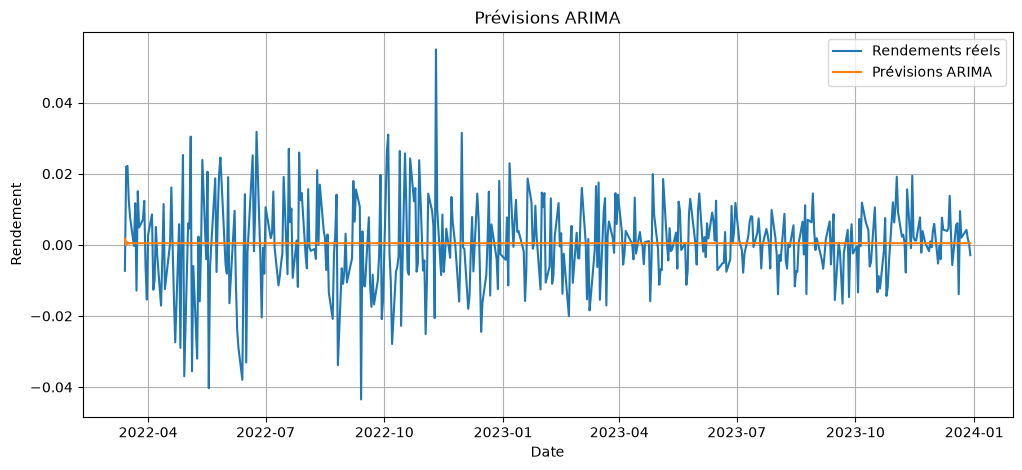

In [26]:
# Comparaison entre rendements réels et prévisions
plt.plot(test_returns.index, test_returns, label="Rendements réels")
plt.plot(test_returns.index, forecast, label="Prévisions ARIMA")
plt.title("Prévisions ARIMA")
plt.xlabel("Date")
plt.ylabel("Rendement")
plt.legend()
plt.grid(True)
plt.show()

 **Pourquoi la prévision est une ligne plate**

`forecast(steps=453)` prédit les 453 jours **d'un coup, depuis la fin du train**, sans jamais voir les vrais rendements du test. Pour l'horizon $h$, la prévision vaut $c + \varphi_1^{h-1}(\dots)$ : comme $|\varphi_1| < 1$, l'influence du dernier jour connu disparaît en quelques jours ($0{,}49^{5} \approx 3\,\%$) et la prévision converge vers la **moyenne** $\mu \approx 0{,}05\,\%$.

En pratique, on fait plutôt une **prévision à un pas glissante** (*rolling one-step-ahead*) : chaque jour, on prévoit le lendemain en utilisant les vrais rendements observés jusqu'à aujourd'hui (paramètres estimés sur le train, sans fuite). C'est ce que fait la cellule suivante, avec des métriques pour comparer à des références naïves.

Référence : prédire 0                  RMSE = 0.01217 | bon sens prédit = sans objet
Référence : moyenne du train           RMSE = 0.01216 | bon sens prédit = 50.8%
ARIMA(1,0,1) multi-pas (énoncé)        RMSE = 0.01217 | bon sens prédit = 50.6%
ARIMA(1,0,1) un pas glissant           RMSE = 0.01234 | bon sens prédit = 50.6%


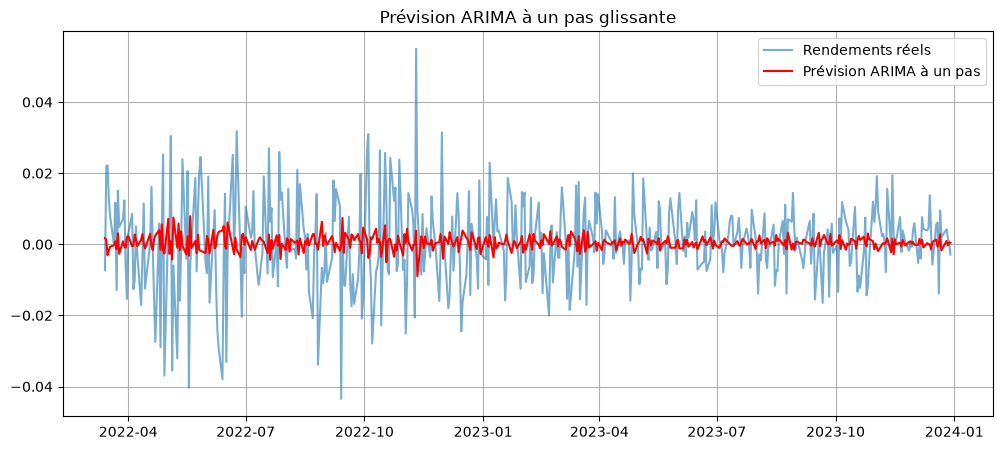

In [27]:
# Prévision à un pas glissante : mêmes paramètres (estimés sur le train),
# mais à chaque date on utilise les vrais rendements passés jusqu'à la veille.
full_result = arima_result.apply(returns.values)
rolling_forecast = pd.Series(
    full_result.get_prediction(start=split_index).predicted_mean,
    index=test_returns.index
)

def evaluate(pred, name):
    rmse = np.sqrt(np.mean((test_returns.values - np.asarray(pred)) ** 2))
    if np.all(np.asarray(pred) == 0):
        direction_txt = "sans objet"   # prédire 0 ne donne aucun sens
    else:
        direction_txt = f"{np.mean(np.sign(np.asarray(pred)) == np.sign(test_returns.values)):.1%}"
    print(f"{name:<38} RMSE = {rmse:.5f} | bon sens prédit = {direction_txt}")

evaluate(np.zeros(len(test_returns)), "Référence : prédire 0")
evaluate(np.full(len(test_returns), train_returns.mean()), "Référence : moyenne du train")
evaluate(forecast.values, "ARIMA(1,0,1) multi-pas (énoncé)")
evaluate(rolling_forecast.values, "ARIMA(1,0,1) un pas glissant")

plt.plot(test_returns.index, test_returns, label="Rendements réels", alpha=0.6)
plt.plot(rolling_forecast.index, rolling_forecast, label="Prévision ARIMA à un pas", color="red")
plt.title("Prévision ARIMA à un pas glissante")
plt.legend(); plt.grid(True); plt.show()

### Q16.5 — Changer les paramètres du modèle

 On teste plusieurs ordres (p, q) et on compare :
- l'**AIC** (critère d'information d'Akaike) calculé sur le **train** : il récompense la qualité d'ajustement et pénalise le nombre de paramètres. **Plus il est bas, mieux c'est.** C'est le critère légitime pour choisir le modèle, car il n'utilise pas le test ;
- la **RMSE de test** en prévision à un pas, uniquement pour constater le résultat a posteriori.

In [28]:
results_arima = []
for p in range(0, 4):
    for q in range(0, 4):
        try:
            res = ARIMA(train_returns, order=(p, 0, q)).fit()
            pred = res.apply(returns.values).get_prediction(start=split_index).predicted_mean
            rmse = np.sqrt(np.mean((test_returns.values - pred) ** 2))
            direction = np.mean(np.sign(pred) == np.sign(test_returns.values))
            results_arima.append(((p, 0, q), res.aic, rmse, direction))
        except Exception as e:
            print((p, 0, q), "échec :", e)

table_arima = pd.DataFrame(results_arima, columns=["ordre", "AIC (train)", "RMSE test", "bon sens prédit"])
table_arima = table_arima.sort_values("AIC (train)").reset_index(drop=True)

rmse_zero = np.sqrt(np.mean(test_returns.values ** 2))
print("RMSE de la référence 'prédire 0' :", round(rmse_zero, 5))
table_arima.round(5)

RMSE de la référence 'prédire 0' : 0.01217


,ordre,AIC (train),RMSE test,bon sens prédit
0,"(3, 0, 2)",-11187.82408,0.01238,0.49007
1,"(2, 0, 3)",-11154.58643,0.01247,0.50552
2,"(0, 0, 3)",-11154.26910,0.01238,0.50993
3,"(0, 0, 2)",-11153.30238,0.01237,0.49007
4,"(2, 0, 0)",-11152.83168,0.01236,0.50110
5,"(1, 0, 3)",-11151.68262,0.01238,0.50773
6,"(3, 0, 0)",-11151.03964,0.01237,0.48786
7,"(2, 0, 1)",-11150.48694,0.01237,0.48786
8,"(3, 0, 3)",-11150.29287,0.01237,0.50331
9,"(1, 0, 2)",-11149.07363,0.01235,0.49890


## Question 16

 **Réponses**

**1. Les prévisions semblent-elles très précises ?**
Non. La prévision multi-pas de l'énoncé devient une **ligne quasi plate** autour de 0,05 % au bout de quelques jours, alors que les vrais rendements oscillent de ±1 à ±4 %. Même la prévision à un pas reste minuscule par rapport aux mouvements réels, et sa RMSE est **pratiquement identique** à celle de la référence « prédire 0 ». Le pourcentage de bon sens prédit tourne autour de 50 %.

**2. Pourquoi la prédiction des rendements financiers reste-t-elle difficile ?**
- L'autocorrélation des rendements est quasi nulle (partie 5) : le passé contient très peu d'information linéaire sur le futur.
- La variance des rendements est dominée par des **chocs imprévisibles** (nouvelles), que ARIMA traite comme du bruit $\varepsilon_t$.
- Les paramètres sont estimés sur 2015-2022 (incluant le Covid) et appliqués à 2022-2023, un régime différent (inflation, hausse des taux) : la dynamique **n'est pas stable**.

**3. Le modèle semble-t-il capturer certaines tendances locales ?**
Très peu. En multi-pas, non : la prévision oublie le passé en quelques jours. En prévision à un pas, il réagit légèrement au rendement de la veille (avec $\varphi_1 < 0$, il anticipe un **petit rebond** après une baisse et un petit recul après une hausse), mais ces ajustements sont de l'ordre de 0,1 %, invisibles face aux variations réelles. Il ne capture pas de vraies tendances.

**4. Pourquoi un faible pouvoir prédictif n'implique-t-il pas nécessairement que le modèle est inutile ?**
- Il nous **apprend quelque chose** : la structure linéaire dans la moyenne est quasi inexistante. C'est un résultat en soi, cohérent avec l'efficience des marchés.
- Il sert de **filtre** : il extrait la (petite) partie prévisible de la moyenne et laisse des résidus $\varepsilon_t$, que l'on peut analyser (partie 7) et modéliser avec GARCH (partie 8). En pratique, on combine souvent ARMA pour la moyenne et GARCH pour la variance.
- Il fournit une **référence** (benchmark) pour juger des modèles plus complexes (ML du TP1).
- Il donne une prévision de la **moyenne** et un **intervalle de prévision**, utiles en gestion du risque même si le point central est peu informatif.

**5. Changer les paramètres du modèle pour faire de meilleures prédictions**
Voir le tableau ci-dessus (les chiffres dépendent de ton exécution). Ce qu'on observe généralement :
- l'**AIC** varie un peu selon (p, q) et le meilleur ordre sur le train peut être plus riche que (1,0,1) ;
- mais la **RMSE de test** est quasiment la même pour tous les ordres, et identique à celle de « prédire 0 » à la 4ᵉ décimale près ; le pourcentage de bon sens prédit reste proche de 50 %.

Conclusion : **changer p et q n'améliore pas significativement les prévisions**. On peut améliorer l'ajustement sur le train, mais pas la capacité à prévoir le futur, car il n'y a presque pas de structure linéaire à exploiter dans la moyenne. Augmenter p et q ajoute surtout des paramètres (risque de surajustement). La structure exploitable se trouve ailleurs : dans la **variance** (GARCH).

---
# PARTIE 7 — Analyse des résidus

 **Concept** : les résidus $\varepsilon_t = X_t - \hat{X}_t$ sont ce que le modèle **n'a pas expliqué**. Un bon modèle doit laisser un **bruit blanc** : moyenne nulle, variance constante, aucune autocorrélation. S'il reste une structure dans les résidus, c'est une information que le modèle a ratée.

In [29]:
# Extraction des résidus
residuals = arima_result.resid
residuals.head()

0   -0.018515
1   -0.012871
2    0.011506
3    0.019283
4   -0.006519
dtype: float64

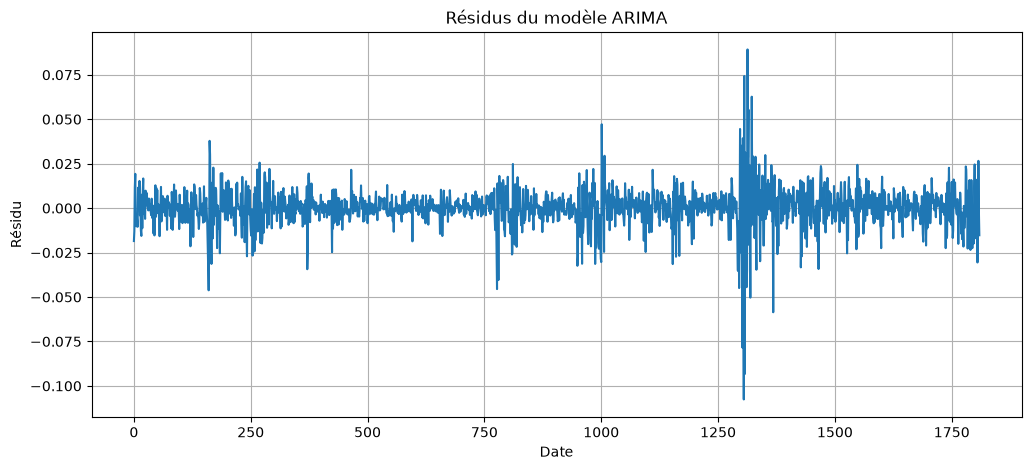

In [30]:
# Visualisation des résidus
plt.plot(residuals)
plt.title("Résidus du modèle ARIMA")
plt.xlabel("Date")
plt.ylabel("Résidu")
plt.grid(True)
plt.show()

## Question 17

 **Réponses**

**1. Les résidus semblent-ils centrés autour de zéro ?**
Oui. Ils oscillent autour de 0 sans tendance (leur moyenne est quasi nulle par construction, la constante du modèle absorbe la moyenne des rendements).

**2. Observez-vous des périodes de fortes fluctuations ?**
Oui, très nettement : début 2018, fin 2018 et surtout **mars 2020**, avec des résidus de ±5 à 10 %. Le graphique des résidus ressemble presque exactement à celui des rendements : ARIMA n'a quasiment rien retiré.

**3. Les résidus ressemblent-ils à un bruit totalement aléatoire ?**
Pas totalement. Leur **moyenne** est stable, mais leur **amplitude** varie fortement dans le temps : périodes calmes et périodes agitées se succèdent en grappes. Un bruit blanc idéal (i.i.d.) aurait une amplitude homogène. Il reste donc une structure : celle de la **variance** (hétéroscédasticité conditionnelle), confirmée par la statistique H ≈ 2,9 du résumé.

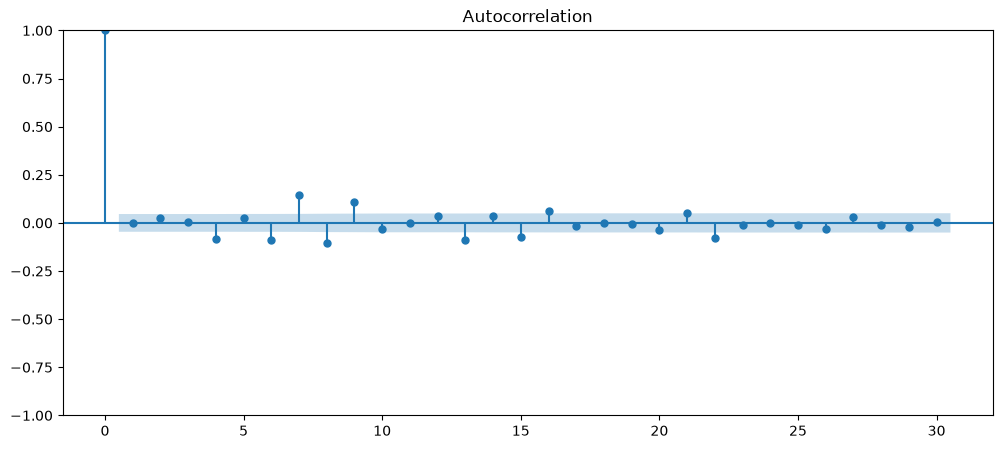

In [31]:
# ACF des résidus
plot_acf(residuals, lags=30)
plt.show()

## Question 18

 **Réponses**

**1. Les résidus présentent-ils encore une forte autocorrélation ?**
Non. Les autocorrélations des résidus sont presque toutes dans la zone bleue. Le test de Ljung-Box au retard 1 du résumé confirme : Q ≈ 0,01, **p ≈ 0,93** → aucune autocorrélation résiduelle au retard 1.

**2. Le modèle ARIMA semble-t-il avoir capturé une partie importante de la dépendance temporelle ?**
Il a capturé **la (petite) dépendance linéaire** qui existait dans la moyenne : les quelques autocorrélations significatives aux premiers retards ont disparu. Mais cette dépendance était faible dès le départ, donc il n'a capturé qu'une **très faible part de la variabilité** des rendements. Et, comme le montre la question 19, il n'a rien capturé de la dépendance dans la **variance**.

**3. Pourquoi l'analyse des résidus est-elle essentielle en modélisation temporelle ?**
- C'est un **diagnostic** : s'il reste de l'autocorrélation, le modèle est mal spécifié (il faut changer p ou q).
- Les intervalles de confiance et les tests du modèle supposent des résidus bruit blanc : si ce n'est pas le cas, ils sont faux.
- Les résidus révèlent **ce que le modèle n'explique pas**, ce qui oriente vers le bon modèle complémentaire (ici GARCH).
- Un bon score d'ajustement ne suffit pas : un modèle peut sembler correct tout en laissant une structure exploitable dans ses erreurs.

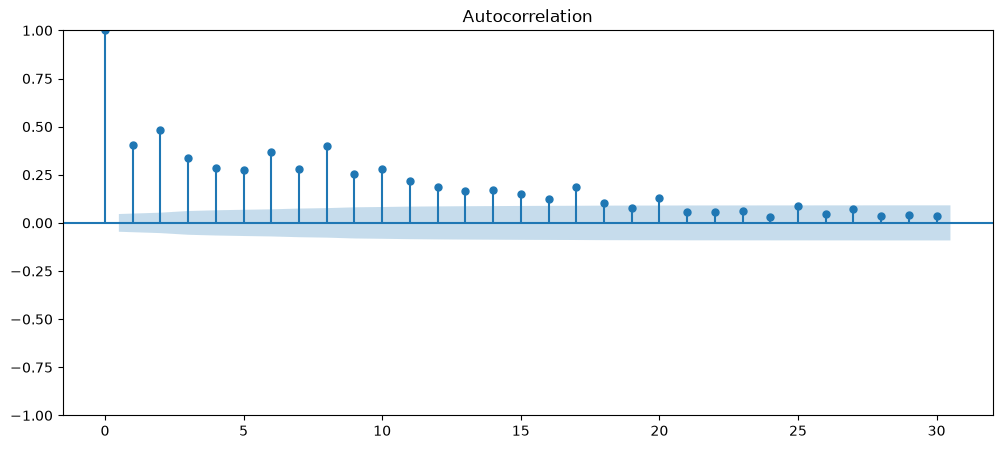

In [32]:
# ACF des résidus au carré
plot_acf(residuals**2, lags=30)
plt.show()

In [33]:
# Bonus : test de Ljung-Box formel sur les résidus et sur les résidus au carré
from statsmodels.stats.diagnostic import acorr_ljungbox

print("Résidus (p-value au retard 10)         :", acorr_ljungbox(residuals, lags=[10])["lb_pvalue"].iloc[0])
print("Résidus au carré (p-value au retard 10) :", acorr_ljungbox(residuals**2, lags=[10])["lb_pvalue"].iloc[0])

Résidus (p-value au retard 10)         : 2.900125247394031e-19
Résidus au carré (p-value au retard 10) : 0.0


## Question 19

 **Réponses**

**1. Pourquoi étudie-t-on également les résidus au carré ?**
Parce que l'ACF des résidus ne teste que la dépendance **dans la moyenne** (le signe et la valeur). Les résidus peuvent être non corrélés mais **pas indépendants** : leur **amplitude** peut avoir une mémoire. $\varepsilon_t^2$ mesure cette amplitude (la variance du jour), donc son ACF teste la dépendance **dans la variance**. C'est le test de l'**effet ARCH**.

**2. Observez-vous une autocorrélation persistante ?**
Oui, très nette : les autocorrélations des résidus au carré sont **positives, significatives et décroissent lentement** sur les 30 retards. Le test de Ljung-Box sur les résidus au carré donne une p-value quasi nulle.

**3. Que suggère ce résultat sur la dynamique de la volatilité ?**
La volatilité a une **mémoire longue** : une période de grandes variations tend à être suivie de grandes variations, et une période calme de calme. C'est le **clustering de volatilité**. La variance des résidus n'est donc pas constante : elle dépend du passé (**hétéroscédasticité conditionnelle**).

**4. Pourquoi le modèle ARIMA semble-t-il insuffisant pour modéliser complètement le risque ?**
ARIMA modélise uniquement la **moyenne conditionnelle** $E[r_t \mid \mathcal{F}_{t-1}]$ et suppose que les chocs ont une **variance constante** $\sigma^2$ (`sigma2` dans le résumé : un seul nombre pour toute la période). Il donne donc le même intervalle de prévision en janvier 2017 (marché calme) et en mars 2020 (krach) : il **sous-estime le risque en crise et le surestime en période calme**. Pour modéliser le risque, il faut un modèle de la **variance conditionnelle** : GARCH.

In [34]:
# TODO : variance empirique des résidus
residual_variance = np.var(residuals)

print("Variance empirique des résidus :", residual_variance)
print("Écart-type correspondant : {:.2%}".format(np.sqrt(residual_variance)))
print("Variance des rendements du train (pour comparaison) :", np.var(train_returns))

Variance empirique des résidus : 0.0001232166636230067
Écart-type correspondant : 1.11%
Variance des rendements du train (pour comparaison) : 0.00012679551543495648


## Question 20

 **Réponses**

**1. Que mesure la variance des résidus ?**
La **dispersion des erreurs** du modèle, c'est-à-dire l'ampleur moyenne de ce qu'il n'explique pas (≈ 0,0001, soit un écart-type ≈ 1,1 % par jour, cohérent avec `sigma2` du résumé). En la comparant à la variance des rendements eux-mêmes, on voit que le modèle n'en réduit qu'une **part infime** : le $R^2$ d'ARIMA est de l'ordre de 1-2 %.

**2. Une faible variance garantit-elle nécessairement un bon modèle ?**
Non :
- Une variance **résiduelle faible sur le train** peut venir du **surajustement** (beaucoup de paramètres qui collent au bruit) et ne pas se retrouver sur le test.
- C'est une valeur **moyenne sur toute la période** : elle cache que l'erreur est minime en période calme et énorme en crise.
- Elle ne dit rien de la **structure** des erreurs : des résidus peuvent avoir une variance faible et rester autocorrélés ou hétéroscédastiques.
- « Faible » n'a de sens qu'en **comparaison** à une référence (variance de la série, modèle naïf).

**3. Pourquoi faut-il également analyser la structure temporelle des résidus ?**
Parce qu'un résumé global (la variance) ne voit pas **comment** les erreurs se répartissent dans le temps. L'ACF des résidus et des résidus au carré révèle s'il reste de l'information exploitable : ici, la variance des résidus semble « normale », mais leur structure montre un fort clustering. C'est cette analyse qui nous dit que le modèle est **incomplet** et qu'il faut modéliser la volatilité.

---
# PARTIE 8 — Modélisation de la volatilité avec GARCH

 **Concept : GARCH(1,1)**

On écrit le rendement comme $r_t = \mu + \varepsilon_t$ avec $\varepsilon_t = \sigma_t z_t$, où $z_t$ est un bruit de variance 1. La **variance conditionnelle** $\sigma_t^2 = \text{Var}(\varepsilon_t \mid \mathcal{F}_{t-1})$ évolue selon :
$$\sigma_t^2 = \omega + \alpha\, \varepsilon_{t-1}^2 + \beta\, \sigma_{t-1}^2$$
- $\omega > 0$ : une **constante** (niveau de base de la variance) ;
- $\alpha\, \varepsilon_{t-1}^2$ : la **réaction au choc d'hier** (composante ARCH) : un grand mouvement hier fait monter la variance aujourd'hui ;
- $\beta\, \sigma_{t-1}^2$ : la **persistance** (composante GARCH) : la variance d'aujourd'hui hérite d'une partie de celle d'hier.

Quantités utiles :
- **persistance** $= \alpha + \beta$ (doit être < 1 pour que la variance soit stationnaire) ;
- **variance de long terme** : $\bar{\sigma}^2 = \dfrac{\omega}{1 - \alpha - \beta}$, le niveau vers lequel la volatilité revient ;
- **demi-vie d'un choc** : $\dfrac{\ln 0{,}5}{\ln(\alpha + \beta)}$, le nombre de jours pour qu'un choc de volatilité soit à moitié résorbé.

In [35]:
# Les modèles GARCH travaillent souvent avec des rendements exprimés en pourcentage
returns_pct = 100 * returns
returns_pct.head()

Date
2015-01-05   -1.805964
2015-01-06   -0.941897
2015-01-07    1.246117
2015-01-08    1.774503
2015-01-09   -0.801357
Name: Close, dtype: float64

In [36]:
# Estimation d'un modèle GARCH(1,1)
garch_model = arch_model(returns_pct, vol="Garch", p=1, q=1)
garch_result = garch_model.fit()

print(garch_result.summary())

Iteration:      1,   Func. Count:      6,   Neg. LLF: 23613.166392546762
Iteration:      2,   Func. Count:     16,   Neg. LLF: 12948.238258868865
Iteration:      3,   Func. Count:     25,   Neg. LLF: 4641.655691030032
Iteration:      4,   Func. Count:     32,   Neg. LLF: 3100.797067493467
Iteration:      5,   Func. Count:     38,   Neg. LLF: 11790.84969416908
Iteration:      6,   Func. Count:     44,   Neg. LLF: 2979.8052392550426
Iteration:      7,   Func. Count:     50,   Neg. LLF: 2928.6584743472777
Iteration:      8,   Func. Count:     55,   Neg. LLF: 2928.6550705578898
Iteration:      9,   Func. Count:     60,   Neg. LLF: 2928.655003144248
Iteration:     10,   Func. Count:     65,   Neg. LLF: 2928.654998167711
Iteration:     11,   Func. Count:     69,   Neg. LLF: 2928.6549981676535
Optimization terminated successfully    (Exit mode 0)
            Current function value: 2928.654998167711
            Iterations: 11
            Function evaluations: 69
            Gradient evaluatio

In [37]:
# Bonus : quantités dérivées des paramètres estimés
params = garch_result.params
omega, alpha, beta = params["omega"], params["alpha[1]"], params["beta[1]"]
persistence = alpha + beta
long_run_vol = np.sqrt(omega / (1 - persistence))

print(f"Persistance alpha + beta       : {persistence:.4f}")
print(f"Volatilité de long terme       : {long_run_vol:.2f} % par jour  (≈ {long_run_vol*np.sqrt(252):.1f} % par an)")
print(f"Demi-vie d'un choc de volatilité : {np.log(0.5)/np.log(persistence):.1f} jours")

Persistance alpha + beta       : 0.9753
Volatilité de long terme       : 1.22 % par jour  (≈ 19.4 % par an)
Demi-vie d'un choc de volatilité : 27.7 jours


## Question 21

 **Réponses** (valeurs de l'énoncé : μ ≈ 0,082 ; ω ≈ 0,037 ; α ≈ 0,197 ; β ≈ 0,779, tous très significatifs)

**1. Que représente le paramètre ω (omega) ?**
La **constante** de l'équation de variance : le niveau plancher de la variance. Seule, elle ne s'interprète pas directement ; c'est avec α et β qu'elle fixe la **variance de long terme** : $\omega/(1-\alpha-\beta) = 0{,}0368/(1-0{,}975) \approx 1{,}48$, soit une volatilité d'équilibre ≈ **1,2 % par jour** (≈ 19 % par an), très cohérente avec l'écart-type mesuré à la question 4.

**2. Que représente le paramètre α (alpha[1]) ?**
La **réaction aux chocs récents** (effet ARCH) : le poids de $\varepsilon_{t-1}^2$, le carré de la surprise d'hier. Avec α ≈ 0,20, un grand mouvement inattendu hier fait **immédiatement monter** la volatilité prévue pour aujourd'hui. Plus α est grand, plus la volatilité est « nerveuse ».

**3. Que représente le paramètre β (beta[1]) ?**
La **persistance** de la volatilité (effet GARCH) : le poids de $\sigma_{t-1}^2$, la variance d'hier. Avec β ≈ 0,78, environ 78 % du niveau de variance d'hier est reporté sur aujourd'hui. Plus β est grand, plus la volatilité évolue **lentement** et les régimes durent.

(Le paramètre μ ≈ 0,082 est le rendement moyen journalier, en % : 0,08 % par jour.)

**4. Pourquoi peut-on dire que GARCH modélise une mémoire du risque ?**
Parce que la variance d'aujourd'hui dépend **récursivement** de la variance d'hier, qui dépend de celle d'avant-hier, etc. : en développant, $\sigma_t^2$ dépend de **tous les chocs passés** avec des poids décroissants $\alpha\beta^k$. La persistance $\alpha + \beta \approx 0{,}975$, très proche de 1, signifie qu'un choc de volatilité met longtemps à se dissiper : sa **demi-vie est d'environ 27 jours** (plus d'un mois de bourse). C'est exactement la traduction mathématique du clustering de volatilité et de l'ACF des rendements au carré qui décroît lentement.

In [38]:
# Extraction de la volatilité conditionnelle
conditional_volatility = garch_result.conditional_volatility
conditional_volatility.head()

Date
2015-01-05    1.028013
2015-01-06    1.249351
2015-01-07    1.207656
2015-01-08    1.199436
2015-01-09    1.311479
Name: cond_vol, dtype: float64

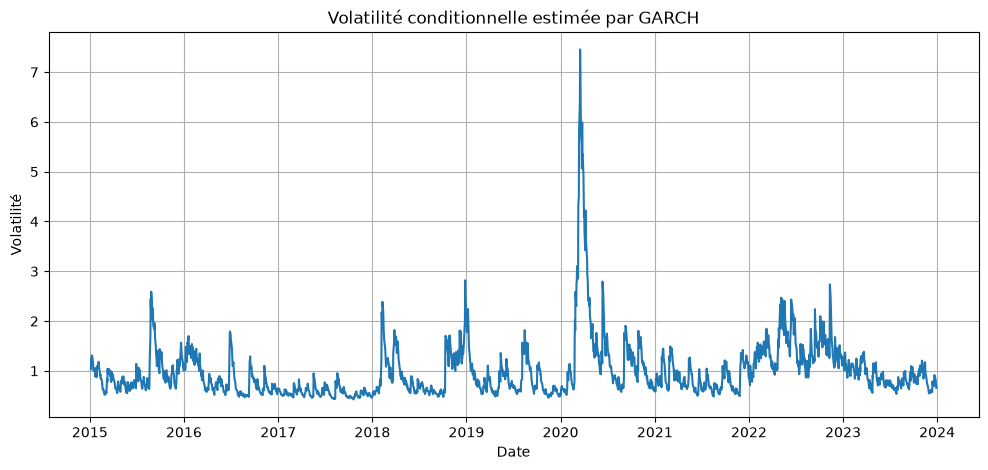

In [39]:
# Visualisation de la volatilité conditionnelle
plt.plot(conditional_volatility)
plt.title("Volatilité conditionnelle estimée par GARCH")
plt.xlabel("Date")
plt.ylabel("Volatilité")
plt.grid(True)
plt.show()

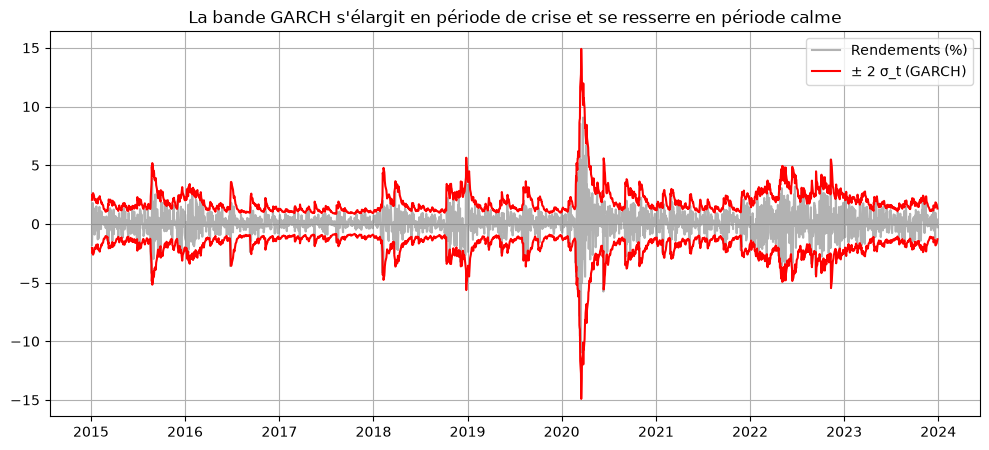

In [40]:
# Bonus : les rendements avec une bande de ± 2 volatilités conditionnelles
plt.plot(returns_pct, color="grey", alpha=0.6, label="Rendements (%)")
plt.plot(2 * conditional_volatility, color="red", label="± 2 σ_t (GARCH)")
plt.plot(-2 * conditional_volatility, color="red")
plt.title("La bande GARCH s'élargit en période de crise et se resserre en période calme")
plt.legend(); plt.grid(True); plt.show()

## Question 22

 **Réponses**

**1. La volatilité estimée semble-t-elle constante dans le temps ?**
Non. Elle varie d'environ **0,4-0,5 %** par jour en période calme (2017, 2019) à plus de **5 %** en mars 2020. Contrairement à ARIMA (variance unique), GARCH produit une volatilité **qui évolue chaque jour**.

**2. Repérez des périodes de forte volatilité.**
- **Août 2015** (dévaluation du yuan, krach chinois) et début 2016 ;
- **Février 2018** (« Volmageddon ») et **décembre 2018** (Fed, guerre commerciale) ;
- **Mars-avril 2020** (Covid), le pic le plus élevé ;
- **2022** (inflation, hausse des taux, guerre en Ukraine), volatilité élevée et durable mais moins extrême ;
- **Mars 2023** (faillite de Silicon Valley Bank), pic plus modéré.

**3. Pourquoi les périodes de crise produisent-elles souvent des pics de volatilité ?**
Les crises génèrent une **succession de chocs importants** (mauvaises nouvelles, annonces d'urgence, ventes forcées, rebonds brutaux). Dans GARCH, chaque grand choc $\varepsilon_{t-1}^2$ fait monter $\sigma_t^2$ via α, et la persistance β maintient ce niveau élevé : une série de chocs fait **grimper la volatilité par paliers**. Économiquement : incertitude maximale, liquidité réduite, mécanismes de vente automatique et panique.

**4. Pourquoi cette information est-elle importante pour la gestion du risque ?**
- Elle permet de calculer une **Value at Risk dynamique** : la perte potentielle de demain dépend de $\sigma_{t+1}$, pas d'une volatilité moyenne.
- Elle permet d'**ajuster l'exposition** : réduire ses positions quand la volatilité monte (*volatility targeting*), augmenter les marges et les couvertures.
- Elle sert à **valoriser les options** et à fixer les exigences de fonds propres.
- Elle est **prévisible** : grâce à la persistance, la volatilité de demain est bien estimée par celle d'aujourd'hui, contrairement au rendement.

In [41]:
# TODO : date de la volatilité conditionnelle maximale
max_conditional_vol_date = conditional_volatility.idxmax()
max_conditional_vol = conditional_volatility.max()

print("Date de volatilité maximale :", max_conditional_vol_date)
print("Volatilité maximale :", max_conditional_vol)

Date de volatilité maximale : 2020-03-17 00:00:00
Volatilité maximale : 7.455243994088187


## Question 23

 **Réponses**

**1. À quel événement financier ou économique ce pic pourrait-il correspondre ?**
Le pic tombe **mi-mars 2020** (autour du 16-17 mars, juste après la chute de −11 % du 16 mars) : c'est le **krach du Covid-19**. Annonces de confinement, arrêt de l'économie, guerre des prix du pétrole entre l'Arabie saoudite et la Russie, coupe-circuits déclenchés plusieurs fois, baisse d'urgence des taux de la Fed à 0 le 15 mars. Le pic GARCH arrive **quelques jours plus tôt** que celui de la volatilité glissante sur 20 jours (question 10), car GARCH réagit immédiatement au choc de la veille alors que la moyenne glissante lisse sur un mois.

**2. Pourquoi les crises créent-elles souvent une persistance de la volatilité ?**
- L'incertitude ne se dissipe pas en un jour : l'évaluation de l'impact d'une crise prend des semaines, chaque nouvelle relance les ajustements.
- Les mécanismes de **désendettement** et de ventes forcées s'étalent dans le temps.
- Les acteurs restent nerveux et réagissent davantage aux nouvelles.
Dans GARCH, cette persistance correspond au paramètre β élevé et à $\alpha + \beta \approx 0{,}975$ : après un choc, la volatilité revient vers sa moyenne de long terme **lentement** (demi-vie ≈ 27 jours).

**3. Pourquoi peut-on dire que le risque évolue par régimes ?**
Parce que la volatilité conditionnelle n'oscille pas au hasard d'un jour à l'autre : elle reste **durablement basse** pendant des mois (2017 : la volatilité la plus faible de la période), puis **saute** vers un niveau élevé lors d'un choc, y reste plusieurs semaines ou mois, et redescend progressivement. On observe une alternance de **régimes calmes et de régimes de stress**. GARCH reproduit cette dynamique de façon continue ; des modèles à changement de régime (Markov switching) la modélisent explicitement.

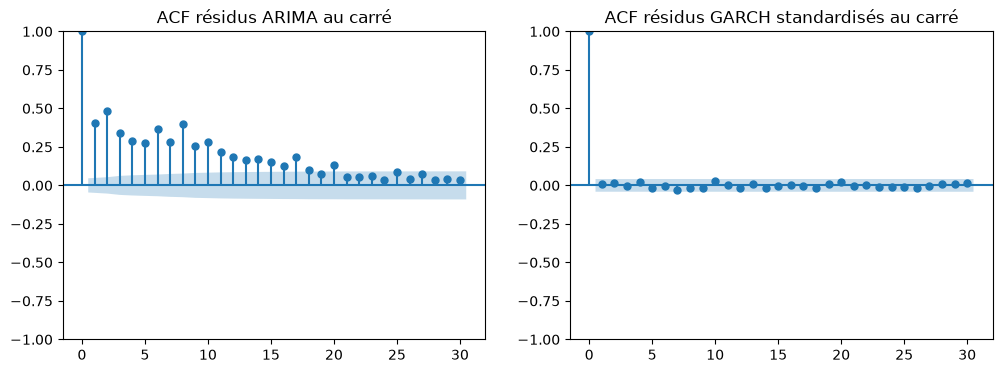

Ljung-Box (retard 10) sur z_t² : p-value = 0.630612440734395


In [42]:
# Bonus : GARCH a-t-il capturé le clustering ? On teste les résidus standardisés z_t = ε_t / σ_t
std_resid = garch_result.std_resid

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(residuals**2, lags=30, ax=axes[0], title="ACF résidus ARIMA au carré")
plot_acf(std_resid**2, lags=30, ax=axes[1], title="ACF résidus GARCH standardisés au carré")
plt.show()

print("Ljung-Box (retard 10) sur z_t² : p-value =", acorr_ljungbox(std_resid**2, lags=[10])["lb_pvalue"].iloc[0])

 **Lecture du bonus** : après division par la volatilité GARCH, l'autocorrélation des carrés **disparaît presque entièrement** (à gauche : forte mémoire ; à droite : quasi plus rien, p-value de Ljung-Box élevée). Autrement dit, GARCH a bien capturé la dynamique de la variance que ARIMA laissait dans ses résidus.

---
# PARTIE 9 — Comparaison ARIMA vs GARCH

## Question 24

| Modèle | Ce qui est principalement modélisé |
|---|---|
| **ARIMA** | La **moyenne conditionnelle** $E[r_t \mid \mathcal{F}_{t-1}]$ : le **niveau / la direction** attendus du rendement, à partir des rendements et des chocs passés. La variance des chocs est supposée **constante**. |
| **GARCH** | La **variance conditionnelle** $\text{Var}(\varepsilon_t \mid \mathcal{F}_{t-1})$ : l'**amplitude attendue** des variations, c'est-à-dire le **risque** et sa dynamique (clustering, persistance). La moyenne est supposée simple (constante). |

Les deux sont **complémentaires** : on combine souvent un **ARMA pour la moyenne + GARCH pour la variance** (ARMA-GARCH).

## Question 25

**Un modèle peut être mauvais pour prédire les rendements tout en restant utile pour modéliser le risque.**

Un rendement contient deux informations : son **signe** (direction) et son **amplitude**. La question 12 a montré qu'elles n'ont pas la même prévisibilité :
- le signe et la valeur de $r_t$ sont quasi **non autocorrélés** → impossible à prévoir ;
- l'amplitude $r_t^2$ est **fortement autocorrélée** → prévisible.

Le GARCH du TP en est l'exemple : sa moyenne est une simple constante (μ ≈ 0,08 %, son $R^2$ affiché vaut **0,000**). Comme prédicteur de rendement, il ne vaut pas mieux que « la moyenne historique ». Pourtant, il prédit très bien que la volatilité de mars 2020 sera 10 fois plus forte que celle de 2017. Pour un gestionnaire de risque, savoir **combien** il peut perdre (VaR, dimensionnement des positions, couverture, prix des options) est aussi précieux que savoir **dans quel sens** le marché va bouger, et beaucoup plus réaliste.

## Question 26

**Prévoir la volatilité est souvent plus réaliste que prévoir parfaitement la direction du marché.**

- **Statistiquement** : la volatilité a une **mémoire forte** (ACF des $r_t^2$ positive et lente, persistance $\alpha + \beta \approx 0{,}975$), alors que les rendements n'ont presque **aucune mémoire** (ACF ≈ 0). On ne peut prévoir que ce qui dépend du passé.
- **Économiquement** : si la direction était prévisible, les investisseurs l'exploiteraient et la feraient disparaître (efficience). Connaître la volatilité future ne donne **pas** de gain d'arbitrage facile : on sait que le marché va beaucoup bouger, mais pas dans quel sens, donc cette prévisibilité peut subsister.
- **Mécaniquement** : les crises ne se résorbent pas en un jour (incertitude, ventes forcées, nervosité), donc un régime agité aujourd'hui annonce un régime agité demain.
- **Empiriquement** : le TP1 n'a pas battu le hasard pour la direction ; ici GARCH reproduit clairement les grandes phases de risque et ses résidus standardisés n'ont plus de mémoire.

---
# PARTIE 10 — Analyse critique des modèles

## Question 27 — Limites des modèles ARIMA

- **Hypothèse de linéarité** : ARIMA suppose que $r_t$ est une **combinaison linéaire** de ses valeurs et chocs passés. Il ne capture ni effets de seuil (réactions différentes en hausse et en baisse), ni interactions, ni dépendances non linéaires (comme la relation entre amplitude passée et amplitude future).
- **Difficulté de prédire les rendements** : comme l'autocorrélation des rendements est quasi nulle, ARIMA n'a presque rien à exploiter. Ses prévisions convergent en quelques pas vers la moyenne (ligne plate) et ne battent pas la référence « prédire 0 » (Q16).
- **Stabilité supposée de la dynamique** : les paramètres sont **fixes** et estimés une fois pour toutes. Or les marchés changent de régime (avant/après Covid, période de taux bas puis de hausse des taux) : les coefficients estimés sur le passé peuvent être faux dans le futur.
- **Variance constante** : ARIMA suppose des chocs de variance $\sigma^2$ fixe, alors que la volatilité varie fortement (H ≈ 2,9, ACF des résidus au carré) : intervalles de prévision faux, risque sous-estimé en crise.
- **Hypothèse de normalité** des chocs, contredite par les queues épaisses (kurtosis ≈ 17,6, Jarque-Bera ≈ 16 000) : les tests de significativité et les intervalles sont peu fiables.
- **Prévision de court terme uniquement** et **univariée** : le modèle n'utilise que le passé de la série, sans aucune information externe (macroéconomie, taux, actualité).

## Question 28 — Limites des modèles GARCH

- **Événements extrêmes** : avec des chocs supposés **normaux** (option par défaut, `Distribution: Normal` dans le résumé), GARCH sous-estime la probabilité des journées extrêmes, même après prise en compte de la volatilité variable. On utilise souvent une loi de Student (`dist="t"`) ou asymétrique pour corriger cela.
- **Réaction en retard** : GARCH réagit **après** les chocs (via $\varepsilon_{t-1}^2$). Il ne peut pas anticiper le **premier** choc d'une crise : la volatilité prévue juste avant le krach de mars 2020 était encore basse.
- **Changements de régime** : les paramètres ω, α, β sont **constants**. Le modèle suppose la même dynamique en 2017 et en 2020 et revient toujours vers la **même** variance de long terme. Il gère mal un changement durable du niveau de risque (nouvelle ère de taux élevés par exemple). La persistance très proche de 1 (0,975) est d'ailleurs souvent le signe de **changements de régime mal modélisés**.
- **Crises financières** : les crises sont des événements rares, avec des mécanismes spécifiques (contagion, liquidité, intervention des banques centrales) que la récursion simple $\sigma_t^2 = \omega + \alpha\varepsilon_{t-1}^2 + \beta\sigma_{t-1}^2$ ne représente pas. Les paramètres estimés sont fortement influencés par ces quelques épisodes.
- **Dépendances non linéaires complexes** : le GARCH standard est **symétrique**, une hausse de 3 % augmente la volatilité autant qu'une baisse de 3 %. Or en pratique, les baisses augmentent davantage la volatilité (**effet de levier**), d'où des extensions comme EGARCH ou GJR-GARCH. Il ne capture pas non plus les liens avec d'autres actifs (contagion entre marchés : il faudrait un GARCH multivarié) ni avec le volume ou les informations externes.
- **Il ne prédit pas la direction** : il ne dit rien du signe des rendements.

## Question 29 — Structure exploitable et composante aléatoire

Les résultats du TP montrent trois niveaux :
1. **Une structure statistique exploitable** :
   - une légère tendance moyenne positive (≈ 0,05 % par jour, la prime de risque) ;
   - une très faible dépendance linéaire à court terme (autocorrélations des rendements légèrement négatives aux premiers retards, capturées par ARIMA) ;
   - surtout, une **dynamique forte de la volatilité** (ACF des carrés, paramètres GARCH très significatifs, persistance 0,975).
2. **Une composante fortement aléatoire** : une fois cette structure retirée, il reste les chocs standardisés $z_t$, qui n'ont plus aucune mémoire (bonus partie 8). Ils représentent l'arrivée de **nouvelles imprévisibles**. Ils dominent la variance des rendements : ARIMA n'explique qu'environ 1-2 % de la variance.

On peut résumer : $r_t = \underbrace{\mu}_{\text{tendance}} + \underbrace{\sigma_t}_{\text{prévisible (GARCH)}} \times \underbrace{z_t}_{\text{imprévisible}}$. Le **niveau de risque** $\sigma_t$ est en bonne partie prévisible, mais le **choc** $z_t$, qui détermine le sens et la surprise du jour, ne l'est pas. Cela explique pourquoi la direction est imprévisible (TP1) alors que le risque est modélisable (TP2).

---
# PARTIE 11 — Ouverture vers le machine learning

## Question 30 — Pourquoi un modèle extrêmement complexe peut-il devenir dangereux en finance ?

- **Surapprentissage** : les séries financières contiennent très peu de signal et beaucoup de bruit (Q29). Un modèle très flexible (réseau profond, LSTM) a assez de capacité pour **mémoriser le bruit** du passé. Il affiche d'excellents résultats sur les données historiques et échoue sur les nouvelles. On l'a vu au TP1 : le réseau de neurones ne battait pas la régression logistique et était le plus instable.
- **Faux signaux** : en testant beaucoup de modèles, de variables et d'hyperparamètres, on finit toujours par trouver une combinaison qui « marche » sur le passé **par hasard** (*data snooping*, sur-optimisation des backtests). Un modèle complexe fournit des signaux d'achat ou de vente avec une apparente confiance, qui ne reposent sur rien de réel. Le risque est financier : on engage de l'argent sur ces signaux.
- **Instabilité des marchés** : la dynamique n'est **pas stationnaire** (changements de régime, crises, nouvelles politiques monétaires). Un modèle complexe s'ajuste finement aux régimes passés et devient faux quand le régime change, souvent précisément pendant une crise, au moment où ses erreurs coûtent le plus. Il réagit aussi fortement à de petites variations des données.
- **Difficulté de généralisation** : peu d'observations indépendantes (une observation par jour, ~2 260 jours ici, très peu de crises) face à des milliers de paramètres ; la validation doit être strictement temporelle (walk-forward), sans fuite d'information, ce qui est facile à rater. Un modèle complexe est aussi une **boîte noire** : difficile de comprendre pourquoi il se trompe, de l'expliquer à un régulateur ou de détecter qu'il a appris un artefact.

**Conclusion** : en finance, la complexité doit être justifiée par un gain mesuré **hors échantillon**, de façon stable sur plusieurs périodes. Des modèles simples et interprétables comme ARIMA et GARCH restent des références indispensables : ce qu'un modèle complexe doit battre pour mériter d'être utilisé.

---
# Conclusion générale

Ce TP montre qu'une série financière se compose de plusieurs couches :
- les **prix** sont non stationnaires (ADF p ≈ 0,90) : on travaille sur les **rendements** (ADF p ≈ 0) ;
- les rendements ont une **dépendance linéaire quasi nulle** : ARIMA ne fait pas mieux que « prédire 0 » ;
- les résidus d'ARIMA conservent une **forte mémoire de leur amplitude** : c'est le clustering de volatilité ;
- **GARCH** capture cette dynamique (α + β ≈ 0,975, demi-vie ≈ 27 jours) et rend les résidus quasi indépendants ;
- il reste une **composante aléatoire irréductible**, les chocs d'information.

L'objectif n'est donc pas de prédire parfaitement le futur, mais d'**identifier la structure réellement exploitable** : ici, elle se trouve beaucoup plus dans le **risque** que dans la **direction**.